<a href="https://colab.research.google.com/github/mcdn-ulima/house-prices/blob/main/S04_A_Regresion_House_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://upload.wikimedia.org/wikipedia/commons/archive/a/a0/20190402132930%21Universidad_de_Lima_logo.png" width="12%" height="90%">

**Maestría en Gestión de la Innovación · Escuela de Posgrado · Universidad de Lima**

# Ciencia de Datos (660947)

## Sesión 4 — Aprendizaje supervisado: regresión lineal

Dataset *House Prices: Advanced Regression Techniques* (Kaggle): viviendas vendidas en Ames, Iowa
(2006–2010). Se carga desde OpenML.

## Entorno


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import joblib

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
np.random.seed(42)

# Colores del notebook: azul para el dato principal, naranja resaltado
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"

def miles(ax, ejes="y"):
    """Formatea los ejes indicados con separador de miles (p. ej. 200,000)."""
    for eje in ejes:
        getattr(ax, f"{eje}axis").set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

## Bloque 1 · El problema supervisado

El modelo aprende la relación entre las variables predictoras (`X`) y una variable objetivo (`y`)
a partir de casos cuya respuesta ya se conoce.

### Paso 1. Cargar el dataset

In [ ]:
URL_RESPALDO = "https://raw.githubusercontent.com/hjhuney/Data/master/AmesHousing/train.csv"

try:
    casas = fetch_openml(name="house_prices", as_frame=True)
    df = casas.frame.copy()
    origen = "OpenML"
except Exception as e:
    # Plan B: copia pública del train.csv de Kaggle
    # (o subir a Colab el train.csv descargado de Kaggle y usar pd.read_csv("train.csv"))
    df = pd.read_csv(URL_RESPALDO)
    origen = "CSV de respaldo"

# OpenML entrega las columnas de texto como 'category'; se pasan a texto simple
columnas_category = df.select_dtypes("category").columns
df[columnas_category] = df[columnas_category].astype(object)

print(f"Origen: {origen} · {df.shape[0]} viviendas, {df.shape[1]} columnas")
df.head()

Origen: OpenML · 1460 viviendas, 81 columnas


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,...,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,...,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,...,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,'Wd Sdng','Wd Shng',...,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
# ¿Regresión o clasificación? Miramos la variable objetivo
print("Tipo:", df["SalePrice"].dtype, "· valores distintos:", df["SalePrice"].nunique())
df["SalePrice"].describe().round(0)

Tipo: int64 · valores distintos: 663


,SalePrice
count,1460.0
mean,180921.0
std,79443.0
min,34900.0
25%,129975.0
50%,163000.0
75%,214000.0
max,755000.0


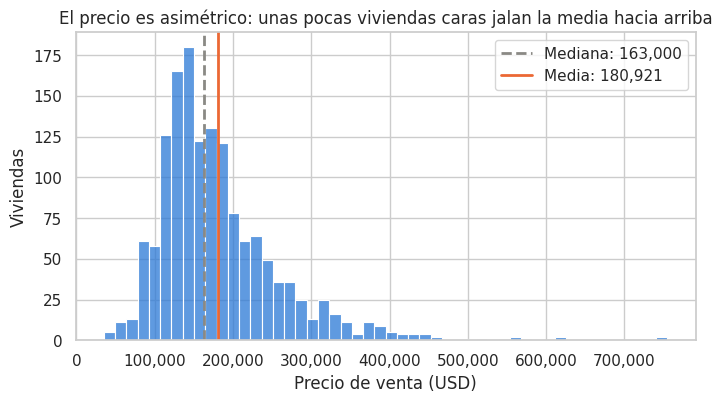

In [ ]:
media, mediana = df["SalePrice"].mean(), df["SalePrice"].median()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["SalePrice"], bins=50, color=AZUL, ax=ax)
ax.axvline(mediana, color=GRIS, linestyle="--", linewidth=2, label=f"Mediana: {mediana:,.0f}")
ax.axvline(media, color=NARANJA, linewidth=2, label=f"Media: {media:,.0f}")
ax.set_title("El precio es asimétrico: unas pocas viviendas caras jalan la media hacia arriba")
ax.set_xlabel("Precio de venta (USD)")
ax.set_ylabel("Viviendas")
miles(ax, "x")
ax.legend()
plt.show()

### Paso 2. Calidad de datos: cuando `NA` no significa "falta el dato"

Según el diccionario de datos (`data_description.txt`), en varias columnas `NA` significa
**"la vivienda no tiene"** (piscina, callejón, cerca, chimenea, garaje, sótano…). Imputar la moda
ahí sería un error de *significado*, no de código.

In [ ]:
faltantes = df.isna().sum()
faltantes[faltantes > 0].sort_values(ascending=False)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
FireplaceQu,690
LotFrontage,259
GarageCond,81
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [ ]:
# Regla tomada del diccionario de datos: NA = "no tiene"
columnas_na_es_ninguno = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]
df[columnas_na_es_ninguno] = df[columnas_na_es_ninguno].fillna("Ninguno")

faltantes = df.isna().sum()
faltantes[faltantes > 0].sort_values(ascending=False)   # lo que queda sí son datos faltantes

,0
LotFrontage,259
GarageYrBlt,81
MasVnrArea,8
Electrical,1


### Paso 3. *Feature engineering* mínimo: pies² → m²

In [ ]:
PIES2_POR_M2 = 10.764
df["area_m2"]   = df["GrLivArea"]   / PIES2_POR_M2   # área habitable sobre el nivel del suelo
df["sotano_m2"] = df["TotalBsmtSF"] / PIES2_POR_M2   # área total del sótano

df[["GrLivArea", "area_m2", "TotalBsmtSF", "sotano_m2"]].describe().round(1)

,GrLivArea,area_m2,TotalBsmtSF,sotano_m2
count,1460.0,1460.0,1460.0,1460.0
mean,1515.5,140.8,1057.4,98.2
std,525.5,48.8,438.7,40.8
min,334.0,31.0,0.0,0.0
25%,1129.5,104.9,795.8,73.9
50%,1464.0,136.0,991.5,92.1
75%,1776.8,165.1,1298.2,120.6
max,5642.0,524.2,6110.0,567.6


### Paso 4. `train_test_split` antes de ajustar cualquier modelo

In [ ]:
train, test = train_test_split(df, test_size=0.2, random_state=42)
print("Train:", train.shape, "· Test:", test.shape)

Train: (1168, 83) · Test: (292, 83)


### Paso 5. La idea del modelo lineal

Mínimos cuadrados ordinarios (OLS) elige la recta que hace mínima la suma de los errores al
cuadrado.
Cada distancia vertical entre un punto y la recta es un **residuo**.

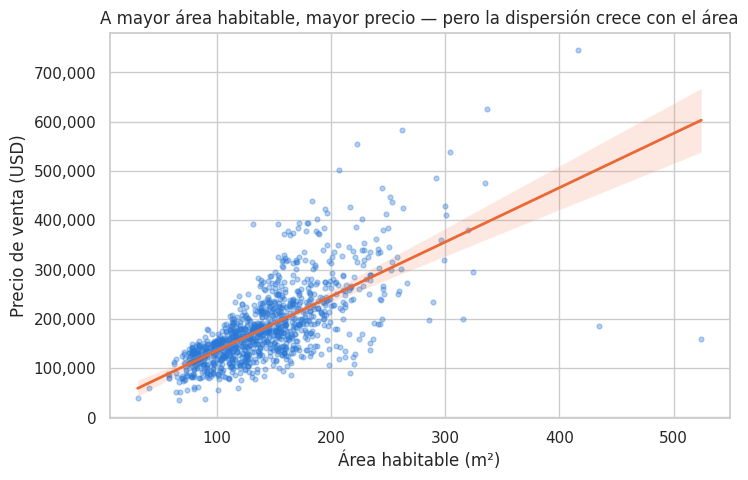

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(
    data=train, x="area_m2", y="SalePrice", ax=ax,
    scatter_kws={"s": 12, "alpha": 0.35, "color": AZUL},
    line_kws={"color": NARANJA, "linewidth": 2},
)
ax.set_title("A mayor área habitable, mayor precio — pero la dispersión crece con el área")
ax.set_xlabel("Área habitable (m²)")
ax.set_ylabel("Precio de venta (USD)")
miles(ax)
plt.show()

In [ ]:
# Regresión simple: una sola variable
modelo_simple = smf.ols("SalePrice ~ area_m2", data=train).fit()
print(f"Sin controlar nada más, cada m² adicional se asocia con {modelo_simple.params['area_m2']:,.0f} USD más.")

Sin controlar nada más, cada m² adicional se asocia con 1,103 USD más.


In [ ]:
modelo_simple.params

,0
Intercept,24899.748157
area_m2,1103.191154


In [ ]:
modelo_simple.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              SalePrice   R-squared:                       0.484
Model:                            OLS   Adj. R-squared:                  0.483
Method:                 Least Squares   F-statistic:                     1093.
Date:                Fri, 18 Sep 2026   Prob (F-statistic):          1.08e-169
Time:                        22:52:27   Log-Likelihood:                -14416.
No. Observations:                1168   AIC:                         2.884e+04
Df Residuals:                    1166   BIC:                         2.885e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    2.49e+04   5005.211      4.975      0.000    1.51e+04    3.47e+04
area_m2     1103.1912     33.363     33.066      0.000    1037.733    1168.649
==============================================================================
Omnibus:                      189.026   Durbin-Watson:                   2.000
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2473.723
Skew:                           0.274   Prob(JB):                         0.00
Kurtosis:                      10.108   Cond. No.                         462.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Regresión lineal múltiple

In [ ]:
formula = "SalePrice ~ area_m2 + OverallQual + YearBuilt + GarageCars + sotano_m2 + C(CentralAir)"

modelo_ols = smf.ols(formula, data=train).fit()
modelo_ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              SalePrice   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     608.7
Date:                Fri, 18 Sep 2026   Prob (F-statistic):               0.00
Time:                        22:30:16   Log-Likelihood:                -13972.
No. Observations:                1168   AIC:                         2.796e+04
Df Residuals:                    1161   BIC:                         2.799e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept          -6.588e+05   9.53e+04     -6.917      0.000   -8.46e+05   -4.72e+05
C(CentralAir)[T.Y]  7382.2599   4766.865      1.549      0.122   -1970.374    1.67e+04
area_m2              527.2240     30.765     17.137      0.000     466.862     587.586
OverallQual         2.032e+04   1272.656     15.969      0.000    1.78e+04    2.28e+04
YearBuilt            294.6509     50.482      5.837      0.000     195.604     393.698
GarageCars          1.508e+04   2033.008      7.419      0.000    1.11e+04    1.91e+04
sotano_m2            269.3363     33.624      8.010      0.000     203.366     335.307
==============================================================================
Omnibus:                      382.675   Durbin-Watson:                   2.029
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            30966.711
Skew:                          -0.551   Prob(JB):                         0.00
Kurtosis:                      28.201   Cond. No.                     1.69e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.69e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Propuesto 1
#### Agregue la variable`GarageArea` (área del garaje) al modelo y discuta el resultado.

Propuesto 2

#### Excluya las filas correspondientes a las viviendas atípicas y cambie la variable target a `log(SalePrice)`. Aplique por igual en train y en test.

Propuesto 3
#### Paso final. Auditoría de IA

1. Copien la salida de `modelo_log.summary()` en un asistente de IA (Gemini, Claude o ChatGPT).
2. Pídanle: *"Interpreta estos resultados para el gerente de una inmobiliaria."*